# Shor's Algorithm: Period Finding and Factoring

**Course**: Quantum Computing Laboratory  
**Version**: 2.4  
**Last Updated**: December 2025

---

## 🔐 Breaking RSA: The Algorithm That Scared Cryptographers

## 📚 Theory

### The Problem
**Given**: Large integer N  
**Find**: Prime factors p and q where N = p × q

### Classical Complexity
- Best known: Sub-exponential
- For 2048-bit N: Billions of years

### Quantum Complexity
- **Polynomial time!**
- Feasible for large N (given enough qubits)

### Algorithm Overview
1. **Classical**: Choose random a < N
2. **Classical**: Check gcd(a, N) ≠ 1 (easy factor)
3. **Quantum**: Find period r of f(x) = a^x mod N
4. **Classical**: Use period to find factors

### Key Insight
Quantum computers excel at **period finding** → This solves factoring!

In [1]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister   # circuits and their named qubit / bit registers
from qiskit.circuit.library import QFTGate              # the Quantum Fourier Transform as a ready-made gate; .inverse() gives QFT†
from qiskit_aer import AerSimulator                     # local classical simulator of a quantum computer
from qiskit_aer.primitives import SamplerV2             # the Qiskit 2.x "primitive" that runs circuits and returns per-register counts
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager   # transpiler: circuit -> the backend's gate set
import numpy as np                     # numerical arrays, np.argmax, np.pi
from math import gcd                   # greatest common divisor (Euclid's algorithm)
from fractions import Fraction         # exact rational numbers (not used below: the notebook codes continued fractions by hand)
from IPython.display import display                      # show a figure (e.g. a circuit drawing) from the middle of a cell
def draw(qc, fold=-1, **kw): return qc.draw("mpl", style="clifford", fold=fold, **kw)   # every circuit picture: matplotlib drawer; fold=-1 = one long row, fold=N wraps after N columns

import qiskit; print(f'✓ Qiskit {qiskit.__version__} ready')


✓ Qiskit 2.1.2 ready


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `QuantumRegister`, `ClassicalRegister` | named groups of qubits / classical bits: the circuit below has a counting register and a 4-qubit work register, and a classical register called `meas` |
| `QFTGate(n)` | Qiskit's library QFT on n qubits as one gate; `.inverse()` is the QFT† that ends every phase-estimation circuit |
| `AerSimulator`, `SamplerV2`, `generate_preset_pass_manager` | the execution stack of the IBM edition: simulator, the primitive that samples it, and the transpiler that rewrites our gates for it |
| `draw(qc)` | our one-line helper around `qc.draw("mpl", style="clifford", fold=...)`; `display()` shows a figure that is not the last line of a cell |

</details>


## 🔨 Period Finding

### Function: f(x) = a^x mod N
Find period r where f(x+r) = f(x) for all x

In [2]:
def classical_period(a, N):
    """
    Find period classically (for verification).
    
    Args:
        a: Base
        N: Modulus
    
    Returns:
        Period r
    """
    r = 1
    result = a                        # a^1
    while result != 1:                # keep multiplying until the cycle closes: a^r = 1 mod N
        result = (result * a) % N     # a^(r+1) mod N; reducing at every step keeps the numbers small
        r += 1
    return r                          # brute force: r multiplications, i.e. exponential in the number of digits of N

# Example: a=7, N=15
a, N = 7, 15                          # tuple assignment: two variables in one line
r_classical = classical_period(a, N)
print(f'Classical period finding:')
print(f'  a={a}, N={N}')
print(f'  Period r = {r_classical}')
print(f'\nVerification:')
for x in range(6):
    print(f'  f({x}) = {a}^{x} mod {N} = {pow(a, x, N)}')   # pow(a, x, N) = a^x mod N by repeated squaring, never building the big number a^x


Classical period finding:
  a=7, N=15
  Period r = 4

Verification:
  f(0) = 7^0 mod 15 = 1
  f(1) = 7^1 mod 15 = 7
  f(2) = 7^2 mod 15 = 4
  f(3) = 7^3 mod 15 = 13
  f(4) = 7^4 mod 15 = 1
  f(5) = 7^5 mod 15 = 7


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `while result != 1: result = (result * a) % N` | the definition of the order: the smallest r ≥ 1 with aʳ ≡ 1 (mod N); the loop walks the cycle a, a², a³, … until it returns to 1 |
| `r += 1` | `r = r + 1`; the counter is the exponent reached so far |
| `pow(a, x, N)` | three-argument `pow` = modular exponentiation: Python squares and reduces as it goes, so it stays fast for huge exponents |
| `f'\nVerification:'` | an f-string; `\n` is a line break. `f'{a}^{x}'` inserts the values of the variables |

</details>


<details open><summary><b>📐 Working it out</b></summary>

**The order of 7 modulo 15 by hand.** Multiply by 7 and reduce:

$$7^1 = 7,\qquad 7^2 = 49 = 3\cdot 15 + 4 \equiv 4,\qquad 7^3 \equiv 4\cdot 7 = 28 \equiv 13,\qquad 7^4 \equiv 13\cdot 7 = 91 = 6\cdot 15 + 1 \equiv 1 .$$

The cycle closes after four steps, so $r = 4$ — the number the cell prints. The six values of the verification loop, $1, 7, 4, 13, 1, 7$, repeat with period 4: $f(x+4) = f(x)$.

*Why the cycle must close.* $\gcd(7, 15) = 1$, so multiplication by 7 is a bijection on $\{1, \dots, 14\}$: the sequence $7^x$ cannot enter a loop that misses $1$, and by Euler's theorem $7^{\varphi(15)} = 7^{8} \equiv 1$, so $r$ divides $8$: the only candidates were $1, 2, 4, 8$.

</details>


## 🎯 Quantum Period Finding: The Deep Connection to Phase Estimation

Shor's algorithm is fundamentally an application of **Quantum Phase Estimation (QPE)**. Understanding this connection is crucial for grasping why the circuit has its particular structure.

### The Modular Multiplication Operator

We define the unitary operator $U$ that performs multiplication by $a$ modulo $N$:

$$U|y\rangle = |ay \mod N\rangle$$

This operator is unitary because multiplication by $a$ (when $\gcd(a,N)=1$) is a permutation of the integers $\{0, 1, ..., N-1\}$.

### Eigenstates of U

The key insight is that $U$ has eigenstates of the form:

$$|u_s\rangle = \frac{1}{\sqrt{r}} \sum_{k=0}^{r-1} e^{-2\pi i sk/r} |a^k \mod N\rangle$$

where $s \in \{0, 1, ..., r-1\}$ and $r$ is the period we seek.

### Eigenvalues Encode the Period!

When $U$ acts on these eigenstates:

$$U|u_s\rangle = e^{2\pi i s/r}|u_s\rangle$$

The eigenvalue is $e^{2\pi i s/r}$, so the **phase is $s/r$**. If we can measure this phase, we can extract $r$ from the denominator!

### Why Powers of 2?

Phase Estimation requires applying controlled-$U^{2^q}$ operations. Here's why:

Each counting qubit $q$ controls $U^{2^q}$:

```
qubit 0  ──●──  controls U^1   = U^(2^0)
qubit 1  ──●──  controls U^2   = U^(2^1)
qubit 2  ──●──  controls U^4   = U^(2^2)
qubit 3  ──●──  controls U^8   = U^(2^3)
  ...
qubit 7  ──●──  controls U^128 = U^(2^7)
```

After the Hadamard gates, each counting qubit is in $|+\rangle = \frac{1}{\sqrt{2}}(|0\rangle + |1\rangle)$.

When controlled-$U^{2^q}$ acts on an eigenstate $|u_s\rangle$:

$$|0\rangle|u_s\rangle \rightarrow |0\rangle|u_s\rangle$$
$$|1\rangle|u_s\rangle \rightarrow e^{2\pi i \cdot 2^q \cdot s/r}|1\rangle|u_s\rangle$$

So qubit $q$ accumulates a phase of $2^q \cdot (s/r)$.

### The Complete Picture

After all controlled-$U$ operations, the counting register contains:

$$\frac{1}{2^{n/2}} \sum_{x=0}^{2^n-1} e^{2\pi i x \cdot s/r}|x\rangle$$

This is exactly the state that the **inverse QFT** transforms into a sharp peak at $|\tilde{x}\rangle$ where:

$$\tilde{x} \approx 2^n \cdot \frac{s}{r}$$

### Binary Phase Encoding

The powers of 2 encode the phase bit-by-bit:
- Qubit 0 → least significant bit of the phase
- Qubit 1 → second bit
- ...
- Qubit n-1 → most significant bit

The inverse QFT then "reads out" this binary-encoded phase into a measurable computational basis state.

### Circuit Structure
1. Counting register (n qubits) - for phase estimation
2. Working register (m qubits) - stores $|a^x \mod N\rangle$
3. Controlled modular exponentiation: encodes phase information
4. Inverse QFT on counting register: extracts phase
5. Measure → Extract period from continued fractions

In [3]:
def c_amod15(a, power):
    """
    Controlled multiplication by a^power mod 15.
    
    This implements U^power where U|y⟩ = |ay mod 15⟩.
    Simplified implementation for N=15 using SWAP gates.
    
    Args:
        a: Base (must be coprime to 15)
        power: Exponent (typically 2^q for phase estimation)
    
    Returns:
        Controlled gate implementing a^power mod 15
    """
    if a not in [2, 4, 7, 8, 11, 13]:
        raise ValueError("'a' must be coprime to 15")   # raise = abort with an error message (1 and 14 are excluded too: their orders 1 and 2 give nothing)
    
    U = QuantumCircuit(4)                 # the 4-qubit work register, no classical bits; qubit 0 = least significant bit of y
    
    for _ in range(power):                # the textbook construction: U^power = U repeated `power` times (`_` = a loop variable we never use)
        if a in [2, 13]:                  # ×2 mod 15 = cyclic shift of the 4 bits upwards (16 ≡ 1, so the top bit wraps to the bottom)
            U.swap(2, 3)                  # U.swap(i, j) exchanges qubits i and j
            U.swap(1, 2)
            U.swap(0, 1)
        if a in [7, 8]:                   # ×8 = ×2⁻¹ mod 15: the same shift downwards
            U.swap(0, 1)
            U.swap(1, 2)
            U.swap(2, 3)
        if a in [4, 11]:                  # ×4 = shift by two places
            U.swap(1, 3)
            U.swap(0, 2)
        if a in [7, 11, 13]:              # 7 = 15 − 8, 11 = 15 − 4, 13 = 15 − 2: complement every bit (y → 15 − y) after the shift
            for q in range(4):
                U.x(q)                    # U.x(q) = NOT (Pauli X) on qubit q
    
    U = U.to_gate()                       # pack the circuit into one reusable Gate (a box in the drawings)
    U.name = f"{a}^{power} mod 15"        # the label shown in the drawings
    c_U = U.control()                     # add ONE control qubit -> controlled-U^power
    return c_U

print('✓ Modular exponentiation gate defined')


✓ Modular exponentiation gate defined


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `for _ in range(power)` | the textbook way to get U^power: repeat U. Cheap to write, expensive to run: qubit 7 controls U¹²⁸ = 128 × 7 gates, and the whole circuit has 255 copies of U |
| `QuantumCircuit(4)` | 4 qubits, no classical bits: the work register that stores y ∈ {0, …, 15}; U permutes its basis states |
| `U.swap(2, 3); U.swap(1, 2); U.swap(0, 1)` | three swaps = a cyclic shift of the bits: bit 3 → 0, bit 0 → 1, …, i.e. y → 2y mod 15 (16 ≡ 1 makes the wrap-around correct); the reverse order shifts the other way (×8) |
| `for q in range(4): U.x(q)` | complement every bit: y → 15 − y; since −1 ≡ 14 this turns ×8 into ×7, ×4 into ×11, ×2 into ×13 (−y ≡ 15 − y mod 15) |
| `U.to_gate()`, `U.name = ...`, `U.control()` | circuit → gate → controlled gate: the box in the drawings, with one extra control wire; `.control()` controls every gate inside |
| the cost | after transpilation to CNOT + 1-qubit gates this circuit has ≈ 31 000 gates (printed in the execution cell); on IQM's native PRX + CZ it is ≈ 70 000 — seven times the 10 000-instruction cap of IQM Resonance. The IQM edition therefore computes a^power mod 15 classically and applies one multiplication |

</details>


<details open><summary><b>📐 Working it out</b></summary>

**Where the swaps send each basis state (a = 7).** Write $y = 8b_3 + 4b_2 + 2b_1 + b_0$ with qubit $i$ holding bit $b_i$.

*The three swaps* `swap(0,1)`, `swap(1,2)`, `swap(2,3)` move the bits $(b_0, b_1, b_2, b_3) \to (b_1, b_0, b_2, b_3) \to (b_1, b_2, b_0, b_3) \to (b_1, b_2, b_3, b_0)$: the new value is $b_1 + 2b_2 + 4b_3 + 8b_0$. Since $16 \equiv 1 \pmod{15}$ this is $8y \bmod 15$ — e.g. $y = 1 = 0001 \to 1000 = 8$, and $8 \cdot 1 = 8$ ✓; $y = 3 = 0011 \to 1001 = 9$, and $8 \cdot 3 = 24 \equiv 9$ ✓.

*The four X gates* complement every bit: $y \to 15 - y$. Together: $y \to 15 - 8y \equiv -8y \equiv 7y \pmod{15}$ because $-8 \equiv 7$. Check: $1 \to 15 - 8 = 7$ ✓, $7 \to 15 - 56 + 45 = 4$ ✓ ($56 \equiv 11$, $15 - 11 = 4$), $4 \to 15 - 32 + 30 = 13$ ✓, $13 \to 15 - 104 + 90 = 1$ ✓: the cycle $1 \to 7 \to 4 \to 13 \to 1$ of order 4.

*The two states nobody uses.* $0 \leftrightarrow 15$ are swapped (the X gates map $0000 \leftrightarrow 1111$), whereas $7 \cdot 0 = 0$. Harmless: the work register starts in $\lvert 1\rangle$ and multiplication by 7 keeps it in $\{1, 7, 4, 13\}$; the permutation printed by the next cell shows `0: 15` for that reason and the check skips $y = 0$.

*The other bases.* `swap(2,3)`, `swap(1,2)`, `swap(0,1)` is the opposite rotation, $y \to 2y$; `swap(1,3)`, `swap(0,2)` is two places, $y \to 4y$; and the complement turns $2, 4, 8$ into $13, 11, 7$.

</details>


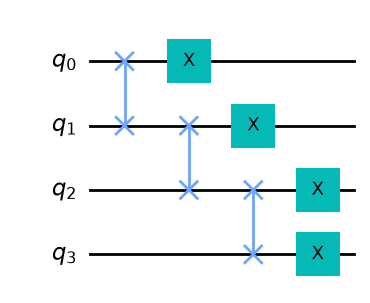

↑ U = multiplication by 7 mod 15: three swaps (a cyclic shift of the 4 bits = ×8) then four X gates (complement = 15 − y), i.e. 7y = 15 − 8y mod 15
U|y⟩ = |7y mod 15⟩ : {0: 15, 1: 7, 2: 14, 3: 6, 4: 13, 5: 5, 6: 12, 7: 4, 8: 11, 9: 3, 10: 10, 11: 2, 12: 9, 13: 1, 14: 8, 15: 0} | correct for y = 1 … 14: True


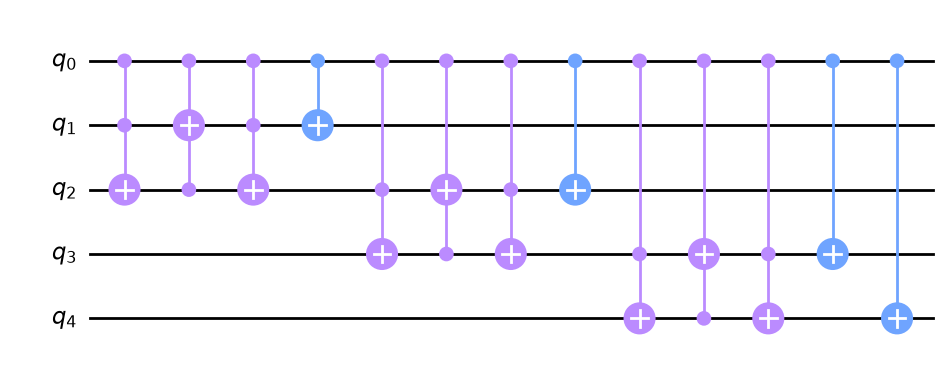

↑ controlled-U after decompose(): every SWAP became a controlled SWAP (Fredkin, cswap) and every X a CNOT — {'ccx': 9, 'cx': 4}


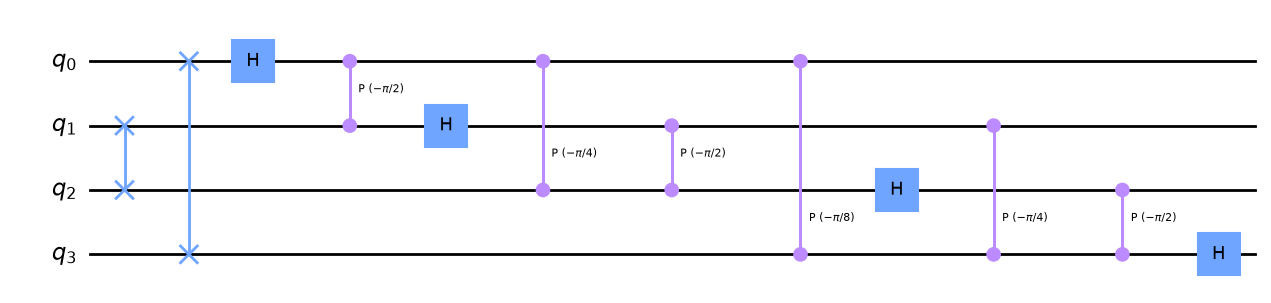

↑ QFT† on 4 qubits: the swaps reverse the qubit order, then Hadamards interleaved with controlled phases of −π/2, −π/4, −π/8


In [4]:
# U for a = 7, power = 1: multiplication by 7 mod 15 on the 4-qubit work register
U7 = c_amod15(7, 1).base_gate.definition          # .base_gate = the gate without its control; .definition = the circuit it was built from
display(draw(U7)); print("↑ U = multiplication by 7 mod 15: three swaps (a cyclic shift of the 4 bits = ×8) then four X gates (complement = 15 − y), i.e. 7y = 15 − 8y mod 15")

# Check the permutation: where does U send each basis state |y⟩?
from qiskit.quantum_info import Operator          # the matrix of a circuit
M = Operator(U7).data                             # 16×16 permutation matrix: M[y', y] = 1 if U|y⟩ = |y'⟩
perm = [int(np.argmax(np.abs(M[:, y]))) for y in range(16)]   # column y has its single 1 in row y' = the image of y
print("U|y⟩ = |7y mod 15⟩ :", {y: perm[y] for y in range(16)},
      "| correct for y = 1 … 14:", all(perm[y] == 7 * y % 15 for y in range(1, 15)))   # 0 ↔ 15 are swapped: never used

# The controlled version placed in a 5-qubit circuit (qubit 0 = control), expanded one level
cU = QuantumCircuit(5)
cU.append(c_amod15(7, 1), [0, 1, 2, 3, 4])        # append(gate, qubits): control qubit first, then the 4 work qubits
display(draw(cU.decompose())); print(f"↑ controlled-U after decompose(): every SWAP became a controlled SWAP (Fredkin, cswap) and every X a CNOT — {dict(cU.decompose().count_ops())}")

# The inverse QFT on 4 qubits, as QFTGate builds it
iqft = QuantumCircuit(4); iqft.append(QFTGate(4).inverse(), range(4))   # the QFT† gate placed in a circuit so that decompose() can open it
display(draw(iqft.decompose())); print("↑ QFT† on 4 qubits: the swaps reverse the qubit order, then Hadamards interleaved with controlled phases of −π/2, −π/4, −π/8")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `gate.base_gate.definition` | a controlled gate remembers the gate it controls (`base_gate`); every custom gate remembers the circuit it was built from (`definition`) |
| `Operator(U7).data` | the 16×16 matrix of the 4-qubit circuit; for a permutation it has a single 1 per column, and `np.argmax` of column y finds its row = where \|y⟩ goes |
| `all(perm[y] == 7 * y % 15 for y in range(1, 15))` | the correctness check of the gate on the 14 states that matter (0 ↔ 15 are interchanged by the X gates, but the register never holds them) |
| `cU.decompose()` | expand composite gates by one level: controlled-(swap, x) → cswap (Fredkin) + cx; call it twice to reach Toffolis and CNOTs |
| `QFTGate(4).inverse()` | the library QFT† as a gate; appending it to a circuit and calling `decompose()` reveals the standard swaps + H + controlled-phase pattern |

</details>


### Build Shor Circuit

In [5]:
def shor_circuit(a, N=15, n_count=8):
    """
    Shor's algorithm circuit for factoring N=15.
    
    The circuit implements Quantum Phase Estimation to find
    eigenvalues of the modular multiplication operator U.
    
    Args:
        a: Base (coprime to N)
        N: Number to factor
        n_count: Number of counting qubits (precision)
    
    Returns:
        QuantumCircuit implementing Shor's algorithm
    """
    cr = ClassicalRegister(n_count, 'meas')      # n_count classical bits, named 'meas' (the name used to read the counts)
    qr = QuantumRegister(n_count + 4)            # counting qubits 0 … n_count-1, then the 4-qubit work register
    qc = QuantumCircuit(qr, cr)
    
    # Step 1: Initialize counting qubits in superposition
    # Creates: (1/√2^n) Σ|x⟩ for x = 0 to 2^n - 1
    for q in range(n_count):
        qc.h(q)                                  # Hadamard: |0⟩ -> |+⟩ on every counting qubit
    
    # Step 2: Initialize working register to |1⟩
    # This is important: |1⟩ = Σ|u_s⟩ (superposition of all eigenstates)
    qc.x(n_count)                                # X on the first (least significant) work qubit: |0000⟩ -> |0001⟩ = |1⟩
    
    qc.barrier(label='Init')                     # a visual separator in the drawing (also stops the transpiler optimising across it)
    
    # Step 3: Apply controlled-U^(2^q) operations
    # Each qubit q controls U^(2^q), encoding phase information
    # This is the heart of Phase Estimation
    for q in range(n_count):
        qc.append(c_amod15(a, 2**q), [q] + list(range(n_count, n_count + 4)))   # append(gate, qubits): control q first, then the 4 work qubits
    
    qc.barrier(label='Mod Exp')
    
    # Step 4: Apply inverse QFT to extract phase
    # Transforms phase-encoded state into computational basis
    qc.append(QFTGate(n_count).inverse(), range(n_count))   # QFT† on the counting register only
    
    qc.barrier(label='IQFT')
    
    # Step 5: Measure counting register
    qc.measure(range(n_count), range(n_count))   # measure(qubits, bits): qubit q -> bit q; the work register is not measured
    
    return qc


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `ClassicalRegister(n_count, 'meas')`, `QuantumRegister(n_count + 4)` | named registers; the result is read back as `data.meas` (IBM) or as the plain bitstring of the only classical register (IQM) |
| `qc.h(q)` on 0 … n_count−1, `qc.x(n_count)` | \|+⟩ on every counting qubit; \|0001⟩ = \|1⟩ on the work register — the uniform superposition of all eigenstates \|u_s⟩, so the measured phase is a random s/r |
| `qc.append(c_amod15(a, 2**q), [q] + ...)` | controlled-U^(2^q) with counting qubit q as control: the QPE pattern, higher qubits get higher powers = higher bits of the phase |
| `QFTGate(n_count).inverse()` | the inverse QFT turns the phase-encoded register into the binary number m ≈ 2ⁿ·s/r |
| `qc.barrier(label=...)` | labelled barriers only structure the drawing (Init / Mod Exp / IQFT); they add no gate |
| `qc.measure(range(n_count), range(n_count))` | qubit q → classical bit q; bit 0 is the rightmost character of the measured string |

</details>


Shor circuit for a=7, N=15:
  Depth: 11
  Size: 26


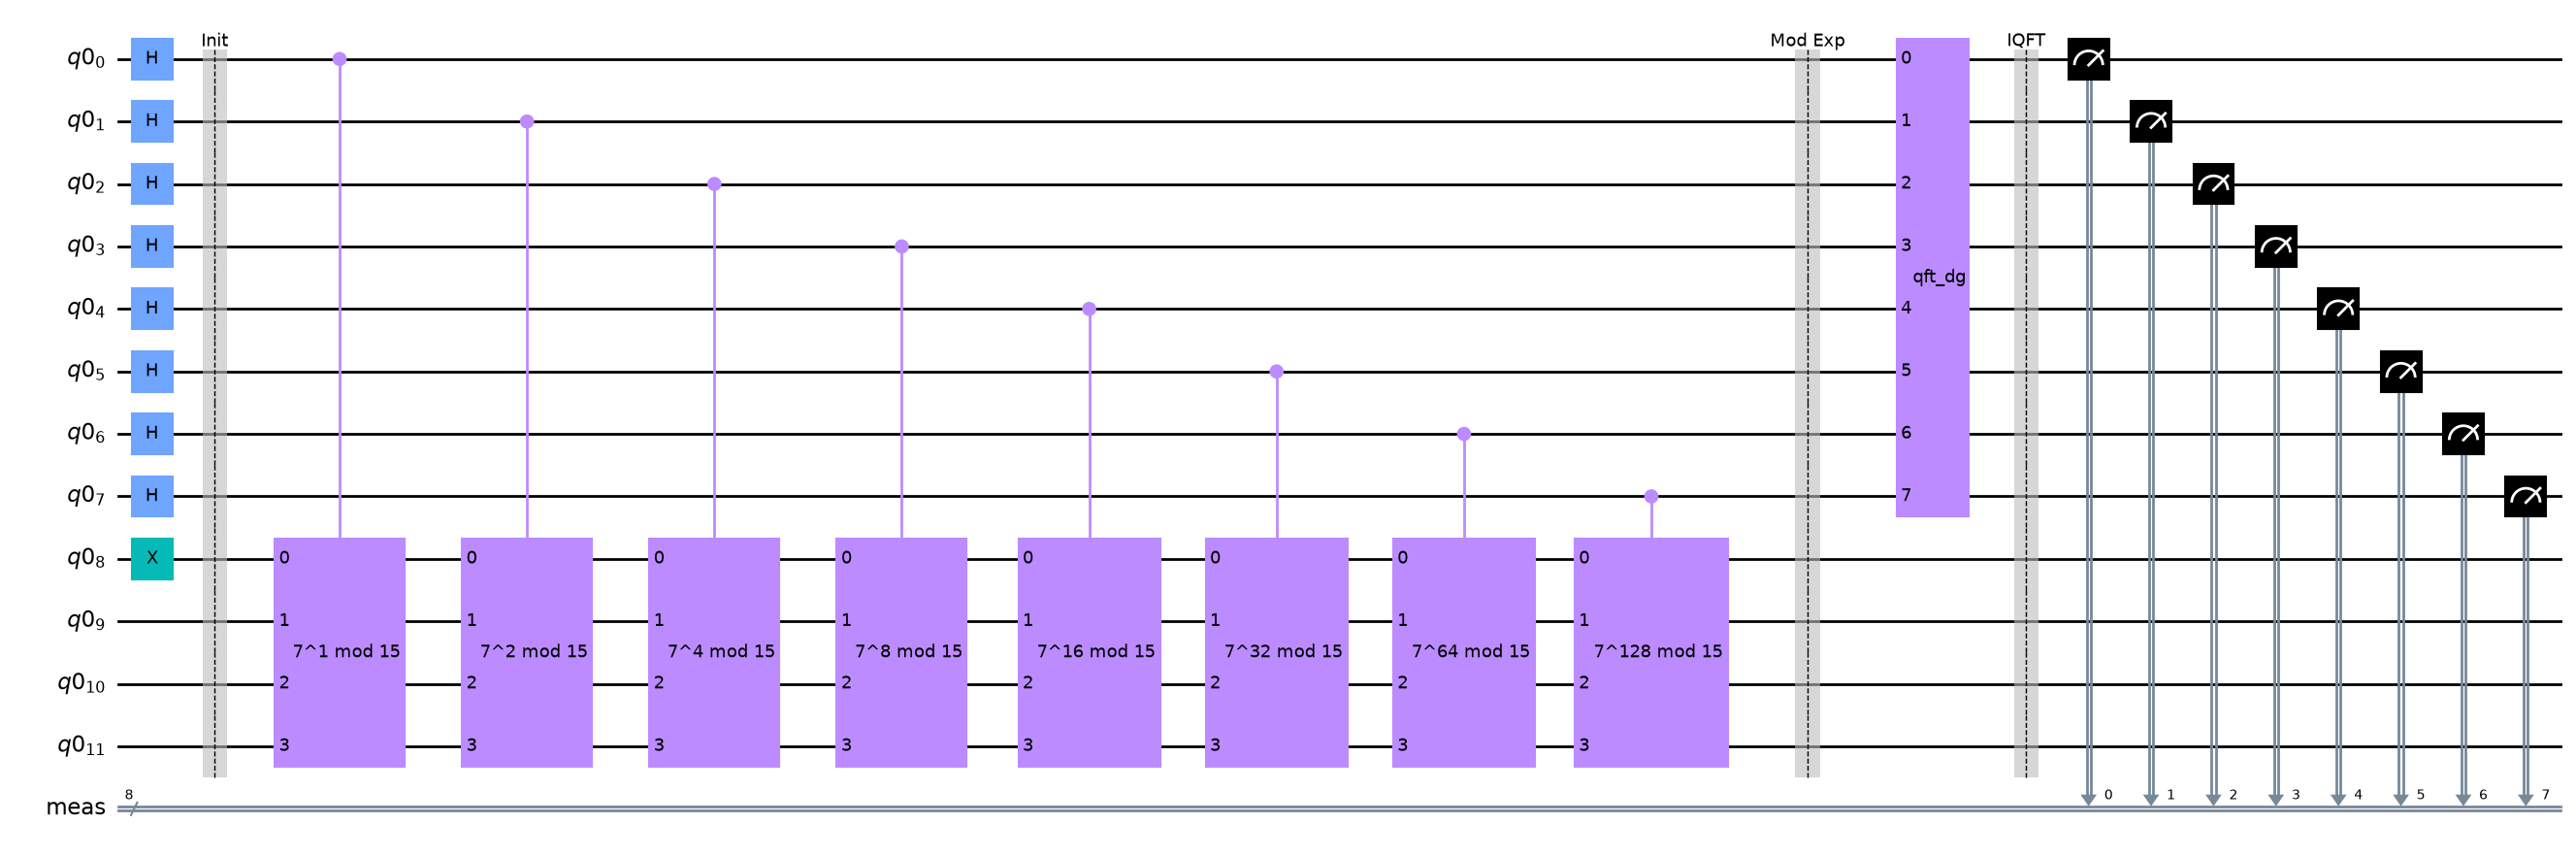

↑ the circuit we run: 8 counting qubits (top) and the 4-qubit work register (bottom); each box is controlled-U^(2^q) with its power in the label, 'IQFT' is QFT†, then the counting register is measured into 'meas'


In [6]:
# Create circuit for a=7, N=15
a_shor = 7
N_shor = 15
qc_shor = shor_circuit(a_shor, N_shor)
print(f'Shor circuit for a={a_shor}, N={N_shor}:')
print(f'  Depth: {qc_shor.depth()}')            # layers of gates that cannot run in parallel (custom gates count as one layer each here)
print(f'  Size: {qc_shor.size()}')              # number of instructions at this level: 8 H + X + 8 boxes + QFT† + 8 measurements (+ barriers are not counted)
display(draw(qc_shor)); print(f"↑ the circuit we run: 8 counting qubits (top) and the 4-qubit work register (bottom); each box is controlled-U^(2^q) with its power in the label, 'IQFT' is QFT†, then the counting register is measured into 'meas'")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `qc_shor.depth()`, `qc_shor.size()` | statistics at the level of our custom boxes: 26 instructions, depth 11. The real cost appears only after transpilation (next cell) |
| `display(draw(qc_shor))` | the QPE skeleton: H layer, the staircase of controlled powers (qubit q controls U^(2^q)), QFT†, measurements |
| the box labels `7^1 mod 15` … `7^128 mod 15` | the eight controlled multiplications; in the IBM edition each box contains 2^q copies of U, in the IQM edition one multiplication by 7^(2^q) mod 15 |

</details>


### Execute and Find Period

In [7]:
simulator = AerSimulator()                                 # local ideal (noise-free) simulator
sampler = SamplerV2()                                      # Aer's Sampler primitive: runs circuits, returns the counts of each classical register
pm = generate_preset_pass_manager(optimization_level=1, backend=simulator)   # the transpiler, configured for this backend (level 1 = light optimisation)
transpiled = pm.run(qc_shor)                               # unroll our custom boxes into gates the simulator knows
print(f'transpiled for Aer: {transpiled.size()} gates, depth {transpiled.depth()}, {dict(transpiled.count_ops())}')   # count_ops(): {gate name: count}
# The cost of the textbook construction (U repeated 2^q times) in a universal basis of CNOT + 1-qubit gates:
basic = generate_preset_pass_manager(optimization_level=1, basis_gates=['cx', 'u']).run(qc_shor)
print(f'the same circuit in a CNOT + U3 basis: {basic.size()} gates, {basic.count_ops()["cx"]} of them CNOTs '
      f'(on IQM native gates ≈ 70 000 instructions: a real device would refuse it — see the IQM edition)')

job = sampler.run([transpiled], shots=2048)                # a list of circuits ("pubs"); shots = number of repetitions
result = job.result()
counts = result[0].data.meas.get_counts()                  # result[0] = first circuit; .data.meas = the classical register named 'meas'; {bitstring: count}

def run_circuit(circuit, shots=2048):
    """Transpile + run + counts in one call (used by the In-depth analysis at the end)."""
    return sampler.run([pm.run(circuit)], shots=shots).result()[0].data.meas.get_counts()

print('Top measurement results:')
for bitstring, count in sorted(counts.items(), key=lambda x: -x[1])[:8]:   # sort by count, descending (the lambda returns −count); keep the first 8
    decimal = int(bitstring, 2)                            # base-2 string -> integer m
    phase = decimal / (2**8)                               # φ = m / 2^n
    print(f'  |{bitstring}⟩ → {decimal} → phase ≈ {phase:.4f} | Count: {count}')


transpiled for Aer: 3372 gates, depth 3298, {'ccx': 2295, 'cx': 1020, 'cp': 28, 'h': 16, 'measure': 8, 'swap': 4, 'barrier': 3, 'x': 1}
the same circuit in a CNOT + U3 basis: 31289 gates, 13328 of them CNOTs (on IQM native gates ≈ 70 000 instructions: a real device would refuse it — see the IQM edition)
Top measurement results:
  |10000000⟩ → 128 → phase ≈ 0.5000 | Count: 518
  |00000000⟩ → 0 → phase ≈ 0.0000 | Count: 516
  |11000000⟩ → 192 → phase ≈ 0.7500 | Count: 515
  |01000000⟩ → 64 → phase ≈ 0.2500 | Count: 499


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `generate_preset_pass_manager(optimization_level=1, backend=simulator)`, `pm.run(qc_shor)` | the transpiler: our custom boxes are unrolled into the simulator's gate set (Toffolis, CNOTs, controlled phases); `size()` jumps from 26 to a few thousand |
| `basis_gates=['cx', 'u']` | the same circuit in a universal two-gate basis: ≈ 31 000 gates, 13 000 of them CNOTs — the price of repeating U 255 times. A noisy device cannot run this; the IQM edition shows the fix (one multiplication by a^(2^q) mod 15) |
| `SamplerV2().run([transpiled], shots=2048)` | the Qiskit 2.x primitive: a list of circuits, a number of shots; `.result()[0]` is the result of the first circuit |
| `result[0].data.meas.get_counts()` | counts are stored per classical register, under its name (`meas`): a dict {bitstring: how many shots} |
| `sorted(counts.items(), key=lambda x: -x[1])[:8]` | the eight most frequent outcomes; ideally only four appear — m = 0, 64, 128, 192, i.e. φ = 0, ¼, ½, ¾ with ≈ 512 shots each |
| `run_circuit(circuit, shots)` | the same three steps in one function, used by the In-depth analysis |

</details>


### Understanding the Measurement Results

For a=7, N=15, the period is r=4. The eigenvalues of U are $e^{2\pi i s/4}$ for s=0,1,2,3.

With 8 counting qubits (2^8 = 256), we expect peaks at:

| s | Phase s/r | Expected value 256·(s/r) | Binary |
|---|-----------|--------------------------|--------|
| 0 | 0/4 = 0.00 | 0 | 00000000 |
| 1 | 1/4 = 0.25 | 64 | 01000000 |
| 2 | 2/4 = 0.50 | 128 | 10000000 |
| 3 | 3/4 = 0.75 | 192 | 11000000 |

These four peaks correspond to the four eigenstates $|u_0\rangle, |u_1\rangle, |u_2\rangle, |u_3\rangle$.

## 🔢 Extracting the Period: The Continued Fractions Algorithm

After measurement, we obtain an integer $m$ between 0 and $2^n - 1$. This value is related to the phase by:

$$m \approx 2^n \cdot \frac{s}{r}$$

where $s$ is a random integer in $\{0, 1, ..., r-1\}$ and $r$ is the period we seek.

**The Problem**: We know $m$ and $n$, we need to find $r$. But the measurement only gives us an *approximation* of $s/r$, not the exact fraction!

### Why Do We Need a Sophisticated Method?

Suppose we measure $m = 64$ with $n = 8$ qubits. We compute:

$$\frac{m}{2^n} = \frac{64}{256} = 0.25$$

Now, 0.25 could represent many fractions:
- 1/4 → r = 4
- 2/8 → r = 8  
- 25/100 → r = 100
- 64/256 → r = 256

Which denominator is correct? Intuitively, we want the **smallest denominator** that approximates the measured value well, because $r$ is typically small compared to $2^n$.

### Continued Fractions: The Key Idea

Continued fractions represent a real number as a sequence of increasingly precise "floors":

$$x = a_0 + \cfrac{1}{a_1 + \cfrac{1}{a_2 + \cfrac{1}{a_3 + \cdots}}}$$

Compact notation: $x = [a_0; a_1, a_2, a_3, ...]$

**Fundamental Property**: The convergents (truncations of the continued fraction) are the **best rational approximations** with bounded denominators.

### The Key Theorem

**Theorem**: If $|x - s/r| < 1/(2r^2)$ and $r < N$, then $s/r$ is a convergent of the continued fraction expansion of $x$.

In our case:
- QPE guarantees that $m/2^n$ approximates $s/r$ with error $< 1/2^n$
- If $2^n > 2r^2$, the error is sufficiently small
- Therefore $s/r$ **must** appear among the convergents!

**Choice of n**: This is why we use $n \approx 2\log_2(N)$ counting qubits, ensuring $2^n > N^2 > r^2$.

### Detailed Example: m = 65, n = 8 (Imperfect Measurement)

Suppose we measure $m = 65$ instead of 64 (1-bit error):

$$\frac{65}{256} = 0.25390625$$

**Computing the Continued Fraction of 65/256**:

| Step | Value | Integer Part | Inverse of Remainder |
|------|-------|--------------|----------------------|
| 0 | 0.2539... | 0 | 3.938... |
| 1 | 3.938... | 3 | 1.066... |
| 2 | 1.066... | 1 | 15.25 |
| 3 | 15.25 | 15 | 4 |
| 4 | 4 | 4 | - |

So: $65/256 = [0; 3, 1, 15, 4]$

**Computing Convergents**:

| Index | Continued Fraction | Convergent | Denominator |
|-------|-------------------|------------|-------------|
| 0 | [0] | 0/1 | 1 |
| 1 | [0; 3] | 1/3 | 3 |
| 2 | [0; 3, 1] | 1/4 | 4 |
| 3 | [0; 3, 1, 15] | 16/63 | 63 |
| 4 | [0; 3, 1, 15, 4] | 65/256 | 256 |

The convergent 1/4 has denominator $r = 4$, which is the correct period!

### Which Convergent is Correct? Classical Verification!

**Important**: We cannot know *a priori* which convergent gives the correct period just from the measurement. We must **verify classically** each candidate.

The complete algorithm is:

```
For each convergent with denominator r_candidate:
    1. Test if a^(r_candidate) ≡ 1 (mod N)
    2. If yes → this is the period (or a divisor of it)
    3. If no  → try the next convergent
```

This classical verification is efficient: computing $a^r \mod N$ takes $O(\log r)$ multiplications using fast exponentiation.

In [8]:
def get_convergents(numerator, denominator):
    """
    Compute all convergents of a fraction using continued fractions.
    
    The convergents are the best rational approximations with
    denominators up to each successive bound.
    
    Args:
        numerator: Numerator of the fraction
        denominator: Denominator of the fraction
    
    Returns:
        List of (numerator, denominator) tuples for each convergent
    """
    convergents = []
    
    # Build continued fraction coefficients [a_0; a_1, a_2, ...]
    coeffs = []
    n, d = numerator, denominator
    while d != 0:                       # Euclid's algorithm: the quotients ARE the continued-fraction coefficients
        q = n // d          # Integer part (floor division)
        coeffs.append(q)
        n, d = d, n - q * d  # Remainder and swap (tuple assignment: both right-hand sides are evaluated first)
    
    # Compute convergents using recurrence relation:
    # h_k = a_k * h_{k-1} + h_{k-2}
    # k_k = a_k * k_{k-1} + k_{k-2}
    h_prev, h_curr = 1, coeffs[0]       # numerators h_{-1} = 1, h_0 = a_0
    k_prev, k_curr = 0, 1               # denominators k_{-1} = 0, k_0 = 1
    convergents.append((h_curr, k_curr))
    
    for i in range(1, len(coeffs)):
        h_new = coeffs[i] * h_curr + h_prev
        k_new = coeffs[i] * k_curr + k_prev
        convergents.append((h_new, k_new))   # the i-th convergent h_i / k_i
        h_prev, h_curr = h_curr, h_new       # shift the window by one
        k_prev, k_curr = k_curr, k_new
    
    return convergents, coeffs          # the function returns two values (a tuple); the caller unpacks them

# Demonstrate with our example
print("Continued fraction expansion of 65/256:")
print("="*50)
convergents, coeffs = get_convergents(65, 256)
print(f"Coefficients: [{coeffs[0]}; {', '.join(map(str, coeffs[1:]))}]")   # ', '.join(...) glues strings with a separator; map(str, ...) converts the ints
print(f"\nConvergents:")
for i, (num, den) in enumerate(convergents):   # enumerate gives (index, item); the item is itself unpacked into (num, den)
    print(f"  c_{i} = {num}/{den} = {num/den:.6f}")


Continued fraction expansion of 65/256:
Coefficients: [0; 3, 1, 15, 4]

Convergents:
  c_0 = 0/1 = 0.000000
  c_1 = 1/3 = 0.333333
  c_2 = 1/4 = 0.250000
  c_3 = 16/63 = 0.253968
  c_4 = 65/256 = 0.253906


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `while d != 0: q = n // d; n, d = d, n - q * d` | Euclid's algorithm on (numerator, denominator); the successive quotients q are the coefficients [a₀; a₁, a₂, …] of the continued fraction |
| `h_new = coeffs[i] * h_curr + h_prev`, same for `k` | the three-term recurrence that builds the convergents hᵢ/kᵢ without ever simplifying a fraction; they are the best rational approximations with denominator ≤ kᵢ |
| `return convergents, coeffs` | two return values; `convergents, coeffs = get_convergents(...)` unpacks them |
| `', '.join(map(str, coeffs[1:]))` | string formatting: the coefficients after a₀, converted to strings and glued with commas |
| `for i, (num, den) in enumerate(convergents)` | nested unpacking: the index and the two parts of each tuple |

</details>


<details open><summary><b>📐 Working it out</b></summary>

**The continued fraction of 65/256 by Euclid's algorithm.** Divide, keep the quotient, swap in the remainder:

$$65 = 0\cdot 256 + 65,\quad 256 = 3\cdot 65 + 61,\quad 65 = 1\cdot 61 + 4,\quad 61 = 15\cdot 4 + 1,\quad 4 = 4\cdot 1 + 0 ,$$

so $65/256 = [0;\,3,\,1,\,15,\,4]$ (the last quotient is $4$: the cell prints `[0; 3, 1, 15, 4]`). The recurrence $h_k = a_k h_{k-1} + h_{k-2}$, $k_k = a_k k_{k-1} + k_{k-2}$ with $(h_{-1}, k_{-1}) = (1, 0)$, $(h_0, k_0) = (0, 1)$ gives

$$\tfrac01,\qquad \tfrac{3\cdot 0 + 1}{3\cdot 1 + 0} = \tfrac13,\qquad \tfrac{1\cdot 1 + 0}{1\cdot 3 + 1} = \tfrac14,\qquad \tfrac{15\cdot 1 + 1}{15\cdot 4 + 3} = \tfrac{16}{63},\qquad \tfrac{4\cdot 16 + 1}{4\cdot 63 + 4} = \tfrac{65}{256} .$$

Testing the denominators (next cell): $7^1 = 7$, $7^3 = 343 = 22\cdot 15 + 13$, $7^4 \equiv 1$ ✓ — the convergent $1/4$ gives $r = 4$ although the measurement was one unit off.

**A clean peak, m = 192.** $192/256$: $256 = 1\cdot 192 + 64$, $192 = 3\cdot 64 + 0$, so $[0;\,1,\,3]$ and the convergents are $\tfrac01, \tfrac11, \tfrac{3\cdot 1 + 0}{3\cdot 1 + 1} = \tfrac34$: $r = 4$ at once, and $s = 3$.

**The awkward peak, m = 128.** $128/256 = [0;\,2]$, convergents $\tfrac01, \tfrac12$: the denominator is $2$, a *divisor* of $r$ ($s = 2$ and $r = 4$ share the factor 2). $7^2 = 49 \equiv 4 \ne 1$, so the plain test fails; `find_period_robust` below rescues it by trying $2r = 4$.

**Why a bound on the error suffices.** If $|\phi - s/r| < 1/(2r^2)$ then $s/r$ is a convergent of $\phi$ (Hardy & Wright, Thm 184). QPE guarantees $|m/2^n - s/r| \le 1/2^{n+1}$, and $2^{n} = 256 \ge 2r^2 = 32$ comfortably — which is why 8 counting qubits are more than enough for $N = 15$, and why the general recipe asks for $2^n \ge N^2$.

</details>


In [9]:
def find_period_from_measurement(m, n_qubits, a, N):
    """
    Extract period by testing all convergent denominators.
    
    This is the complete classical post-processing step that
    takes a measurement outcome and finds the period.
    
    Args:
        m: Measured integer from counting register
        n_qubits: Number of counting qubits
        a: Base for modular exponentiation
        N: Number to factor
    
    Returns:
        Period r, or None if not found
    """
    if m == 0:
        return None, "m=0 gives no information"      # phase 0: s = 0, every r fits
    
    # Get all convergents of m / 2^n
    convergents, coeffs = get_convergents(m, 2**n_qubits)
    
    print(f"  Measured m={m}, phase = {m}/{2**n_qubits} = {m/2**n_qubits:.6f}")
    print(f"  Continued fraction: [{coeffs[0]}; {', '.join(map(str, coeffs[1:]))}]")
    print(f"  Convergents: {convergents}")
    print(f"  Testing denominators:")
    
    # Test each denominator as a candidate period
    for num, denom in convergents:
        if denom == 0 or denom > N:                   # the order is at most N − 1: larger denominators are artefacts of the finite precision
            continue                                  # skip to the next convergent
        
        # Classical verification: check if a^denom ≡ 1 (mod N)
        result = pow(a, denom, N)
        if result == 1:
            print(f"    r={denom}: {a}^{denom} mod {N} = 1  ✓ FOUND!")
            return denom, "success"                   # return ends the function at the first success
        else:
            print(f"    r={denom}: {a}^{denom} mod {N} = {result}  ✗")
    
    return None, "no valid period found"

# Test with different measurements
print("="*60)
print("PERIOD EXTRACTION FROM MEASUREMENTS")
print("="*60)
print(f"Parameters: a={a_shor}, N={N_shor}, expected period r={r_classical}")
print()

test_measurements = [64, 65, 128, 192]                # two clean peaks, one off-by-one reading, and the divisor case
for m in test_measurements:
    print(f"\n{'─'*60}")
    print(f"Measurement m = {m}:")
    r, status = find_period_from_measurement(m, 8, a_shor, N_shor)
    print(f"  → Result: r = {r} ({status})")


PERIOD EXTRACTION FROM MEASUREMENTS
Parameters: a=7, N=15, expected period r=4


────────────────────────────────────────────────────────────
Measurement m = 64:
  Measured m=64, phase = 64/256 = 0.250000
  Continued fraction: [0; 4]
  Convergents: [(0, 1), (1, 4)]
  Testing denominators:
    r=1: 7^1 mod 15 = 7  ✗
    r=4: 7^4 mod 15 = 1  ✓ FOUND!
  → Result: r = 4 (success)

────────────────────────────────────────────────────────────
Measurement m = 65:
  Measured m=65, phase = 65/256 = 0.253906
  Continued fraction: [0; 3, 1, 15, 4]
  Convergents: [(0, 1), (1, 3), (1, 4), (16, 63), (65, 256)]
  Testing denominators:
    r=1: 7^1 mod 15 = 7  ✗
    r=3: 7^3 mod 15 = 13  ✗
    r=4: 7^4 mod 15 = 1  ✓ FOUND!
  → Result: r = 4 (success)

────────────────────────────────────────────────────────────
Measurement m = 128:
  Measured m=128, phase = 128/256 = 0.500000
  Continued fraction: [0; 2]
  Convergents: [(0, 1), (1, 2)]
  Testing denominators:
    r=1: 7^1 mod 15 = 7  ✗
    r=2: 7^2 mo

<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `return None, "m=0 gives no information"` | a function may return a tuple (value, message); m = 0 means φ = 0, i.e. s = 0 — any r is compatible |
| `if denom == 0 or denom > N: continue` | only denominators ≤ N can be orders; `continue` jumps to the next convergent |
| `pow(a, denom, N) == 1` | the classical verification that makes the whole scheme safe: a wrong candidate is caught at once, O(log r) multiplications |
| m = 64, 65, 192 → 4; m = 128 → None | the three readings near φ = ¼, ¾ give r = 4; the φ = ½ peak yields the divisor r = 2 and the test fails — the next cell fixes that |

</details>


### What Can Go Wrong?

#### Case 1: m = 128 Fails!

The phase 0.5 = 1/2 gives denominator r = 2, but $7^2 \mod 15 = 4 \neq 1$.

This happens because:
- The true phase is $s/r = 2/4 = 1/2$
- The convergent gives $r = 2$, which is a **divisor** of the true period $r = 4$

**Solutions**:
1. Try multiples: if $r$ doesn't work, try $2r$, $3r$, ...
2. Repeat the algorithm and combine results using LCM
3. Use more measurements and look for patterns

#### Case 2: gcd(s, r) > 1

If $s$ and $r$ share a common factor $g$, the continued fraction gives $r/g$ instead of $r$.

Example: True phase = 2/4 = 1/2 → we get r = 2 instead of r = 4

#### Case 3: m = 0

Measurement $m = 0$ corresponds to phase 0, which gives no information about $r$. Simply discard and repeat.

In [10]:
def find_period_robust(m, n_qubits, a, N, max_multiplier=5):
    """
    Robust period finding that handles divisors of the true period.
    
    If a candidate r doesn't work, also tries multiples 2r, 3r, etc.
    
    Args:
        m: Measured integer
        n_qubits: Number of counting qubits
        a: Base
        N: Number to factor
        max_multiplier: Maximum multiple to try
    
    Returns:
        Period r or None
    """
    if m == 0:
        return None
    
    convergents, _ = get_convergents(m, 2**n_qubits)   # `_` = we ignore the coefficients here
    
    for num, denom in convergents:
        if denom == 0 or denom > N:
            continue
        
        # Try the denominator and its small multiples
        for mult in range(1, max_multiplier + 1):      # mult = 1, 2, 3, 4, 5
            r_candidate = denom * mult
            if r_candidate > N:
                break                                  # leave the inner loop: larger multiples cannot be orders either
            if pow(a, r_candidate, N) == 1:
                return r_candidate                     # first candidate that works (silent version: no printing)
    
    return None

# Test the robust version
print("\nRobust period finding (trying multiples):")
print("="*50)
for m in [64, 65, 128, 192]:
    r = find_period_robust(m, 8, a_shor, N_shor)
    print(f"  m={m:3d} → r = {r}")                     # {m:3d} = integer right-aligned in 3 characters



Robust period finding (trying multiples):
  m= 64 → r = 4
  m= 65 → r = 4
  m=128 → r = 4
  m=192 → r = 4


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `convergents, _ = ...` | unpack a tuple and throw one part away: `_` is the conventional name for an unused value |
| `for mult in range(1, max_multiplier + 1)` | when s and r share a factor g the convergent gives r/g; its multiples 2·(r/g), 3·(r/g), … reach r again (here m = 128 → 2 → 4) |
| `break` vs `continue` | `break` leaves the inner loop (multiples too large), `continue` skips one convergent; `return` leaves the function |
| all four readings → r = 4 | the robust post-processing turns 3 of the 4 ideal outcomes into the period (m = 0 stays useless), i.e. 75 % of the shots are usable |

</details>


### Apply to Actual Quantum Results

In [11]:
print("\nAnalyzing actual measurement results:")
print("="*60)

periods_found = {}                                       # {period: number of shots that led to it}

for bitstring, count in sorted(counts.items(), key=lambda x: -x[1]):   # all outcomes of the run above, most frequent first
    m = int(bitstring, 2)                                # bitstring -> integer m
    r = find_period_robust(m, 8, a_shor, N_shor)         # continued fractions + multiples + classical check
    
    if r:                                                # None counts as False: readings that gave nothing are dropped
        if r not in periods_found:
            periods_found[r] = 0
        periods_found[r] += count                        # accumulate the shots behind each period

print("\nPeriod statistics from quantum measurement:")
for r, cnt in sorted(periods_found.items(), key=lambda x: -x[1]):
    print(f"  r = {r}: {cnt} counts ({100*cnt/2048:.1f}%)")   # percentage of the 2048 shots

print(f"\nExpected period: {r_classical}")



Analyzing actual measurement results:

Period statistics from quantum measurement:
  r = 4: 1532 counts (74.8%)

Expected period: 4


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `for bitstring, count in sorted(counts.items(), ...)` | every outcome of the run, with its multiplicity: each shot is one independent run of the quantum subroutine |
| `periods_found[r] += count` | a histogram of recovered periods weighted by shots; on the ideal simulator 75 % of the shots give r = 4 (m = 64, 128, 192), the m = 0 quarter gives nothing |
| `if r:` | Python truthiness: `None` is False, any non-zero integer is True |
| other periods (8, 12, …) | multiples of 4 also satisfy 7ʳ ≡ 1; on a noisy backend off-peak readings land there. They are still valid exponents — but `factor_from_period` may fail on them (a^(r/2) ≡ 1 gives trivial gcds), which is why the next cell tries the most frequent periods first |

</details>


### Visual Summary of the Extraction Process

```
Measurement: m = 65 (with n=8 qubits)
         ↓
Raw phase: 65/256 = 0.25390625
         ↓
Continued fraction: [0; 3, 1, 15, 4]
         ↓
Convergents: 0/1, 1/3, 1/4, 16/63, 65/256
         ↓
Test denominators:
    r=1: 7^1 mod 15 = 7  ✗
    r=3: 7^3 mod 15 = 13 ✗
    r=4: 7^4 mod 15 = 1  ✓ FOUND!
         ↓
Period r = 4
         ↓
Verify: 7^4 mod 15 = 2401 mod 15 = 1 ✓
```

## 🔓 Factor N Using Period

### Classical Post-processing
Given period r:
1. If r is odd, try again
2. If a^(r/2) ≡ -1 (mod N), try again  
3. Otherwise: gcd(a^(r/2) ± 1, N) gives factors!

### Why This Works

Since $a^r \equiv 1 \pmod{N}$, we have:

$$a^r - 1 \equiv 0 \pmod{N}$$

If r is even, we can factor:

$$(a^{r/2} - 1)(a^{r/2} + 1) \equiv 0 \pmod{N}$$

Unless $a^{r/2} \equiv \pm 1 \pmod{N}$, both factors share non-trivial common factors with N.

In [12]:
def factor_from_period(a, r, N):
    """
    Extract factors of N from the period r.
    
    Uses the relation: (a^(r/2) - 1)(a^(r/2) + 1) ≡ 0 (mod N)
    
    Args:
        a: Base used in period finding
        r: Period found
        N: Number to factor
    
    Returns:
        Tuple (factor1, factor2) or (None, None) if unsuccessful
    """
    if r % 2 == 1:
        return None, None  # Period is odd: a^(r/2) is not an integer
    
    # Check a^(r/2) ≠ -1 (mod N)
    x = pow(a, r // 2, N)                 # x = a^(r/2) mod N, a square root of 1 modulo N (r//2 = integer division)
    if x == N - 1:                        # x ≡ −1: the trivial square root, gcd(x + 1, N) = N tells nothing
        return None, None
    
    # Compute factors using gcd
    factor1 = gcd(x + 1, N)               # N divides (x − 1)(x + 1) but neither factor alone -> the primes split between the two gcds
    factor2 = gcd(x - 1, N)
    
    return factor1, factor2

# Try to factor N=15 using the periods found
print(f'\nFactoring N={N_shor} using a={a_shor}:')
print(f'Periods found: {list(periods_found.keys())}')

for r in sorted(periods_found.keys(), key=lambda x: -periods_found[x])[:3]:   # the three most frequent periods
    f1, f2 = factor_from_period(a_shor, r, N_shor)
    if f1 and f1 != 1 and f1 != N_shor:                  # a non-trivial factor (None, 1 and N are rejected)
        print(f'\n  ✓ Period r={r} → Factors: {f1} and {f2}')
        print(f'    Verification: {f1} × {f2} = {f1 * f2}')
        break                                            # done: leave the loop
    else:
        x = pow(a_shor, r // 2, N_shor) if r % 2 == 0 else None   # conditional expression, for the diagnostic message
        print(f'  Period r={r}: ', end='')               # end='' keeps the next print on the same line
        if r % 2 == 1:
            print('Failed (r is odd)')
        elif x == N_shor - 1:
            print(f'Failed (a^(r/2) = {x} ≡ -1 mod {N_shor})')
        else:
            print(f'Failed (trivial factors)')



Factoring N=15 using a=7:
Periods found: [4]

  ✓ Period r=4 → Factors: 5 and 3
    Verification: 5 × 3 = 15


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `r % 2 == 1` | an odd order cannot be split as x² = aʳ with integer x; the algorithm must retry with another a (for N = 15 every order is 2 or 4, so this never happens here) |
| `x = pow(a, r // 2, N)`; `x == N - 1` | x is a square root of 1 mod N; x ≡ −1 is the trivial root and gives nothing — the second retry condition |
| `gcd(x + 1, N)`, `gcd(x - 1, N)` | Euclid's algorithm: (x − 1)(x + 1) is a multiple of N, neither factor is, so each prime of N = pq sits in exactly one gcd |
| `if f1 and f1 != 1 and f1 != N_shor: ... break` | accept only a non-trivial divisor; `break` stops at the first period that works (r = 4 → 5 and 3) |
| `print(..., end='')` | suppress the line break so the reason of a failure follows on the same line |

</details>


<details open><summary><b>📐 Working it out</b></summary>

**From the order to the factors, a = 7, N = 15.** The order is $r = 4$: even ✓. Then

$$x = a^{r/2} \bmod N = 7^{2} \bmod 15 = 49 - 45 = 4 ,$$

which is neither $1$ nor $14 \equiv -1$ ✓. Because $7^4 \equiv 1$ we know $15 \mid (7^2 - 1)(7^2 + 1) = 3 \cdot 5 = 15$ — and indeed

$$\gcd(x + 1, N) = \gcd(5, 15) = 5, \qquad \gcd(x - 1, N) = \gcd(3, 15) = 3 ,$$

so the cell prints `Factors: 5 and 3` and the step-by-step cell `15 = 5 × 3`.

*Why it had to work.* $N \mid (x - 1)(x + 1)$ with $N \nmid (x - 1)$ (else $x \equiv 1$, contradicting that $r$ is the *smallest* exponent) and $N \nmid (x + 1)$ (the excluded case $x \equiv -1$). Since $N = 3 \cdot 5$, each prime divides one of the two factors and they cannot both divide the same one — that factor would be a multiple of 15. So one prime goes to each gcd.

*A period that is a multiple.* On a noisy backend the table above may also list $r = 8$: $x = 7^4 \equiv 1$, $\gcd(2, 15) = 1$ and $\gcd(0, 15) = 15$ — "trivial factors". That is why the loop tries the most frequent periods first and moves on.

*The base that fails.* $a = 11 \equiv -4$: $r = 2$, $x = 11 = N - 1 \equiv -1$ — exactly the excluded case; Exercise 1 / In-depth task 1 show it.

</details>


### Detailed Factorization Example

Let's trace through the factorization step by step:

In [13]:
# Step-by-step factorization
print(f'Factoring N={N_shor} with a={a_shor}, period r={r_classical}')
print('='*50)

r = r_classical
print(f'\n1. Check if r={r} is even: {"Yes" if r % 2 == 0 else "No"}')   # a conditional expression inside the f-string

x = pow(a_shor, r // 2, N_shor)                                          # x = a^(r/2) mod N
print(f'\n2. Compute x = a^(r/2) mod N = {a_shor}^{r//2} mod {N_shor} = {x}')

print(f'\n3. Check x ≠ N-1: {x} ≠ {N_shor-1}? {"Yes" if x != N_shor-1 else "No"}')

print(f'\n4. Compute factors:')
print(f'   gcd(x+1, N) = gcd({x+1}, {N_shor}) = {gcd(x+1, N_shor)}')
print(f'   gcd(x-1, N) = gcd({x-1}, {N_shor}) = {gcd(x-1, N_shor)}')

f1 = gcd(x+1, N_shor)
f2 = gcd(x-1, N_shor)
print(f'\n5. Result: {N_shor} = {f1} × {f2} ✓')


Factoring N=15 with a=7, period r=4

1. Check if r=4 is even: Yes

2. Compute x = a^(r/2) mod N = 7^2 mod 15 = 4

3. Check x ≠ N-1: 4 ≠ 14? Yes

4. Compute factors:
   gcd(x+1, N) = gcd(5, 15) = 5
   gcd(x-1, N) = gcd(3, 15) = 3

5. Result: 15 = 5 × 3 ✓


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `{"Yes" if r % 2 == 0 else "No"}` | a conditional expression evaluated inside the f-string (note the inner double quotes vs the outer single ones) |
| `pow(a_shor, r // 2, N_shor)` | 7² mod 15 = 4, the non-trivial square root of 1 that makes the factorisation work |
| `gcd(x+1, N_shor)`, `gcd(x-1, N_shor)` | gcd(5, 15) = 5 and gcd(3, 15) = 3: the two primes, one in each gcd |

</details>


## 📊 Summary

### The Complete Algorithm Flow

```
Input: N=15, a=7
    ↓
[Quantum] Hadamard → Controlled-U^(2^q) → Inverse QFT → Measure
    ↓
Measured value: m (e.g., 65)
    ↓
[Classical] Continued fractions of m/2^n → Convergents
    ↓
[Classical] Test each convergent denominator: a^r mod N = 1?
    ↓
Period found: r = 4
    ↓
[Classical] gcd(a^(r/2) ± 1, N) → Factors: 3 and 5
```

### Complexity Comparison
| Method | Time Complexity |
|--------|----------------|
| Trial Division | O(√N) |
| General Number Field Sieve | sub-exponential |
| **Shor's Algorithm** | **O((log N)³)** |

### For RSA-2048
- Classical: ~10^9 years
- Quantum (Shor): Hours with sufficient qubits!

### Requirements
- ~2n qubits for n-bit number
- High-fidelity gates
- Error correction

## 🎓 Exercises

### Exercise 1: Different Base (Easy)
Run Shor for a=11, N=15. Compare period found.

### Exercise 2: Factor 21 (Medium)
Implement simplified Shor for N=21, a=2.

### Exercise 3: Analysis (Hard)
Calculate qubit requirements for factoring RSA-2048.

### Exercise 4: Phase Estimation Deep Dive (Medium)
Verify that the eigenstates $|u_s\rangle$ satisfy $U|u_s\rangle = e^{2\pi i s/r}|u_s\rangle$ for a=7, N=15.

### Exercise 5: Continued Fractions (Medium)
Compute the continued fraction expansion of 85/256 by hand and identify which convergent gives the correct period for a=7, N=15.

## 🔬 In-depth analysis

1. **Other bases.** Run `shor_circuit` for $a = 2, 8, 11, 13$ (this also solves Exercise 1). Turn every measured outcome into a period with `find_period_robust`, keep the most frequent one, and feed it to `factor_from_period`. Which orders do you get, and which base fails — and why (look at $a^{r/2} \bmod 15$)?
2. **Precision.** Run the $a = 7$ circuit with `n_count` = 4 and 10 and measure the fraction of shots that land exactly on the four ideal outcomes $k \cdot 2^{n_{\rm count}}/4$. Then explain the paradox: for $r = 4$ even 4 counting qubits are exact, so why does the theory ask for $2^n \ge N^2$? Compute classically the ideal QPE distribution for a phase that is *not* a dyadic fraction, $\phi = 1/3$ (the order of $a = 4$ modulo $N = 21$), for $n = 4, 6, 8, 10$, and the probability that the convergents of $m/2^n$ recover $r = 3$.
3. **Success rate.** Every shot is an independent run of the quantum subroutine. From a fresh run of the $a = 7$ circuit, estimate the probability that one run yields a non-trivial factor (i) with the first working convergent only and (ii) with `find_period_robust`, and break it down by outcome ($m = 0$, the ideal peaks, off-peak readings). Compare with the ideal values 50 % and 75 %.

Write your code in the empty cell below; a reference solution follows it. Try first, then compare.


In [14]:
# 🔬 In-depth analysis — your code here



In [15]:
# Reference solution
# (1) other bases: run the circuit, turn every outcome into a period, keep the most frequent one, try to factor
for a_ in (2, 8, 11, 13):
    cnt = run_circuit(shor_circuit(a_, 15), shots=512)
    found = {}                                                                    # {period: shots that led to it}
    for bits, c_ in cnt.items():
        r_ = find_period_robust(int(bits, 2), 8, a_, 15)
        if r_: found[r_] = found.get(r_, 0) + c_                                  # dict.get(key, default): 0 the first time
    if not found:
        print(f"(1) a = {a_:2d}: no period recovered (too noisy)"); continue
    r_best = max(found, key=found.get)                                            # the key with the largest value = most frequent period
    f1, f2 = factor_from_period(a_, r_best, 15)
    ok = f1 is not None and 1 < f1 < 15
    print(f"(1) a = {a_:2d}: classical order {classical_period(a_, 15)}, quantum {dict(sorted(found.items()))} -> r = {r_best}, "
          f"factors {(f1, f2) if ok else 'none: a^(r/2) = ' + str(pow(a_, r_best // 2, 15)) + ' ≡ −1 mod 15'}")

# (2a) precision on the backend: r = 4 divides every 2^n, so the four peaks are exact for any n_count (only noise grows with n)
for n_ in (4, 10):
    cnt = run_circuit(shor_circuit(7, 15, n_count=n_), shots=1024)
    peaks = {k * 2 ** n_ // 4 for k in range(4)}                                   # ideal outcomes for r = 4: 0, 2^n/4, 2^n/2, 3·2^n/4
    tot = sum(cnt.values())
    on_peak = sum(c_ for bits, c_ in cnt.items() if int(bits, 2) in peaks) / tot
    r4 = sum(c_ for bits, c_ in cnt.items() if find_period_robust(int(bits, 2), n_, 7, 15) == 4) / tot
    print(f"(2) n_count = {n_:2d}: {2 ** n_:5d} outcomes, {on_peak:.1%} of the shots exactly on the four ideal peaks, {r4:.1%} recover r = 4")

# (2b) a non-dyadic phase, classically: ideal QPE distribution P(m) = |(1/2^n) Σ_x e^{2πi x (φ − m/2^n)}|² for φ = 1/3
phi = 1 / 3                                                                        # the order of 4 mod 21 is 3 (4^3 = 64 = 3·21 + 1)
for n_ in (4, 6, 8, 10):
    x_ = np.arange(2 ** n_)
    P = np.array([abs(np.sum(np.exp(2j * np.pi * x_ * (phi - m_ / 2 ** n_)))) ** 2 for m_ in range(2 ** n_)]) / 4 ** n_
    p_ok = sum(P[m_] for m_ in range(2 ** n_) if find_period_robust(m_, n_, 4, 21) == 3)   # outcomes whose convergents give r = 3
    m_top = int(np.argmax(P))
    print(f"(2) φ = 1/3, n = {n_:2d}: most likely m = {m_top} (P = {P[m_top]:.3f}, m/2^n = {m_top / 2 ** n_:.4f}), "
          f"P(recover r = 3) = {p_ok:.3f}   [the recipe 2^n ≥ N² = 441 asks for n ≥ 9]")

# (3) success per run: each shot is one run of the quantum subroutine; post-process it both ways
cnt = run_circuit(shor_circuit(7, 15), shots=1024)
tot = sum(cnt.values()); plain = robust = 0; by_kind = {}
for bits, c_ in cnt.items():
    m_ = int(bits, 2)
    r1 = next((d for _, d in get_convergents(m_, 256)[0] if 0 < d <= 15 and pow(7, d, 15) == 1), None) if m_ else None   # first convergent that works, no multiples
    r2 = find_period_robust(m_, 8, 7, 15)                                           # with multiples
    ok1 = r1 is not None and factor_from_period(7, r1, 15)[0] not in (None, 1, 15)   # a non-trivial factor?
    ok2 = r2 is not None and factor_from_period(7, r2, 15)[0] not in (None, 1, 15)
    plain += ok1 * c_; robust += ok2 * c_                                           # True * count = count, False * count = 0
    kind = 'm = 0 (no information)' if m_ == 0 else ('ideal peak (64, 128, 192)' if m_ % 64 == 0 else 'off-peak (noise)')
    by_kind.setdefault(kind, [0, 0]); by_kind[kind][0] += c_; by_kind[kind][1] += ok2 * c_
print(f"(3) success per run: {plain / tot:.1%} with the first working convergent, {robust / tot:.1%} trying multiples "
      f"(ideal 50% and 75%: m = 0 never works, m = 128 only through 2r = 4)")
for kind, (n_k, s_k) in sorted(by_kind.items()):
    print(f"    {kind:<28}: {n_k:4d} shots, {s_k / n_k:.0%} of them give a factor")


(1) a =  2: classical order 4, quantum {4: 377} -> r = 4, factors (5, 3)


(1) a =  8: classical order 4, quantum {4: 364} -> r = 4, factors (5, 3)


(1) a = 11: classical order 2, quantum {2: 272} -> r = 2, factors (3, 5)


(1) a = 13: classical order 4, quantum {4: 384} -> r = 4, factors (5, 3)
(2) n_count =  4:    16 outcomes, 100.0% of the shots exactly on the four ideal peaks, 76.4% recover r = 4


(2) n_count = 10:  1024 outcomes, 100.0% of the shots exactly on the four ideal peaks, 72.6% recover r = 4
(2) φ = 1/3, n =  4: most likely m = 5 (P = 0.685, m/2^n = 0.3125), P(recover r = 3) = 0.996   [the recipe 2^n ≥ N² = 441 asks for n ≥ 9]
(2) φ = 1/3, n =  6: most likely m = 21 (P = 0.684, m/2^n = 0.3281), P(recover r = 3) = 1.000   [the recipe 2^n ≥ N² = 441 asks for n ≥ 9]
(2) φ = 1/3, n =  8: most likely m = 85 (P = 0.684, m/2^n = 0.3320), P(recover r = 3) = 1.000   [the recipe 2^n ≥ N² = 441 asks for n ≥ 9]
(2) φ = 1/3, n = 10: most likely m = 341 (P = 0.684, m/2^n = 0.3330), P(recover r = 3) = 1.000   [the recipe 2^n ≥ N² = 441 asks for n ≥ 9]


(3) success per run: 49.1% with the first working convergent, 74.9% trying multiples (ideal 50% and 75%: m = 0 never works, m = 128 only through 2r = 4)
    ideal peak (64, 128, 192)   :  767 shots, 100% of them give a factor
    m = 0 (no information)      :  257 shots, 0% of them give a factor


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `found.get(r_, 0) + c_` | a counting dict: `get(key, default)` avoids a KeyError the first time a period appears |
| `max(found, key=found.get)` | the key with the largest value: the most frequent recovered period |
| a = 11 → `none: a^(r/2) = 11 ≡ −1` | order 2 with 11 ≡ −1 mod 15 — the trivial square root, Shor's second failure mode; a = 2, 8, 13 (order 4) and 4 (order 2, x = 4) all give 3 × 5 |
| `{k * 2 ** n_ // 4 for k in range(4)}` | the ideal register values for r = 4; because 4 divides 2ⁿ they are exact integers for every n ≥ 2 — the on-peak fraction is 100 % without noise and *decreases* with n on a noisy backend (more gates) |
| `abs(np.sum(np.exp(2j*np.pi*x_*(phi - m_/2**n_))))**2 / 4**n_` | the textbook QPE amplitude for a phase φ that is not a multiple of 1/2ⁿ: the peak spreads over neighbours (sin²/sin² envelope); only with enough bits do the convergents of the neighbours still contain 1/3 |
| `next((d for ... if pow(7, d, 15) == 1), None)` | the first convergent denominator that passes the classical test, or None — `find_period_from_measurement` without the printing |
| `ok1 * c_` | booleans are integers: True counts the shots of that outcome, False adds 0 |
| `by_kind.setdefault(kind, [0, 0])` | create the entry [shots, successes] on first use; m = 0 (¼ of the ideal shots) never succeeds, m = 128 only through the multiple 2r, so the ideal rates are 2/4 and 3/4 |

</details>


## 📖 References

1. Shor, P. (1997). *Polynomial-Time Algorithms for Prime Factorization and Discrete Logarithms on a Quantum Computer*. SIAM J. Comput. 26(5), 1484-1509.
2. Nielsen & Chuang, *Quantum Computation and Quantum Information*, Section 5.3
3. Qiskit Textbook: https://learn.qiskit.org/course/ch-algorithms/shors-algorithm
4. Hardy & Wright, *An Introduction to the Theory of Numbers*, Chapter 10 (Continued Fractions)

---

**Version**: 2.4.0  
**License**: MIT